In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

# 设置数据路径（根据你的实际解压位置调整）
DATA_DIR = 'KIT-ML'  # 假设 KIT-ML 文件夹在当前目录

# 加载一个样本
vecs_dir = os.path.join(DATA_DIR, 'new_joint_vecs')
texts_dir = os.path.join(DATA_DIR, 'texts')
motion = np.load(os.path.join(vecs_dir, '00001.npy'))
print("运动数据形状:", motion.shape)

运动数据形状: (47, 251)


左腕位置形状: (47, 3)
右腕位置形状: (47, 3)
第 30 帧原始右手腕位置: [-63.11728287 -32.10569763  52.19091415]


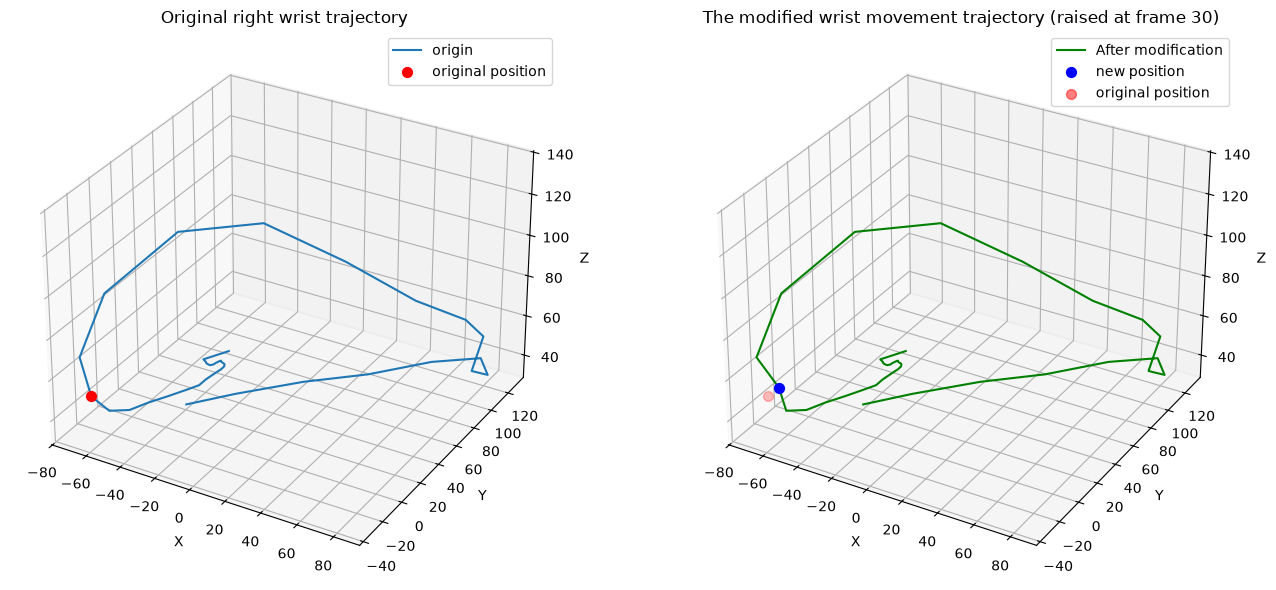


模拟的控制信号：
- 控制的关节：右手腕
- 控制的时间：第 30 帧
- 控制的目标位置：[-63.11728287 -22.10569763  52.19091415]
这相当于 OmniControl 中定义的 'spatial control signal'。


In [4]:
# 1. 定义关节索引（KIT-ML 使用 21 个关节，顺序与 HumanML3D 相同）
# 关节名称: [Root, LHip, RHip, LSpine, RSpine, Spine, LChest, RChest, Neck, Head, 
#            LShoulder, RShoulder, LArm, RArm, LForeArm, RForeArm, LHand, RHand, 
#            LThigh, RThigh, LShin, RShin]
# 为了演示，我们假设右手腕索引为 17（需验证，常见顺序中手索引为 16, 17）
# 若不确定，可先打印所有关节位置观察。

# 2. 提取右手腕的位置（局部坐标，相对于根节点）
def get_joint_pos(motion, joint_idx):
    """提取指定关节的局部位置 (x, y, z)，从第3维开始"""
    start = 3 + joint_idx * 3
    return motion[:, start:start+3]

# 尝试几个可能的手腕索引（根据常见顺序）
left_hand_pos = get_joint_pos(motion, 16)
right_hand_pos = get_joint_pos(motion, 17)

print("左腕位置形状:", left_hand_pos.shape)
print("右腕位置形状:", right_hand_pos.shape)

# 3. 选取第 30 帧作为修改目标
frame_idx = 30

# 原始右手腕位置
original_pos = right_hand_pos[frame_idx].copy()
print(f"第 {frame_idx} 帧原始右手腕位置: {original_pos}")

# 新位置：抬高 0.2 单位（Y方向）
new_pos = original_pos.copy()
new_pos[1] += 10  # Y轴向上

# 4. 创建修改后的运动数据副本
motion_modified = motion.copy()
# 修改右手腕的局部位置
start_idx = 3 + 17 * 3
motion_modified[frame_idx, start_idx:start_idx+3] = new_pos

# 5. 可视化对比：修改前后的右腕 3D 轨迹
fig = plt.figure(figsize=(14, 6))

# 原始轨迹
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot(right_hand_pos[:, 0], right_hand_pos[:, 1], right_hand_pos[:, 2], label='origin')
ax1.scatter(*original_pos, color='red', s=50, label='original position')
ax1.set_title('Original right wrist trajectory')
ax1.set_xlabel('X'); ax1.set_ylabel('Y'); ax1.set_zlabel('Z')
ax1.legend()

# 修改后轨迹
modified_right_hand = get_joint_pos(motion_modified, 17)
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot(modified_right_hand[:, 0], modified_right_hand[:, 1], modified_right_hand[:, 2], label='After modification', color='green')
ax2.scatter(*new_pos, color='blue', s=50, label='new position')
ax2.scatter(*original_pos, color='red', s=50, alpha=0.5, label='original position')
ax2.set_title('The modified wrist movement trajectory (raised at frame 30)')
ax2.set_xlabel('X'); ax2.set_ylabel('Y'); ax2.set_zlabel('Z')
ax2.legend()

plt.tight_layout()
plt.show()

# 6. 输出控制信号的含义
print("\n模拟的控制信号：")
print(f"- 控制的关节：右手腕")
print(f"- 控制的时间：第 {frame_idx} 帧")
print(f"- 控制的目标位置：{new_pos}")
print("这相当于 OmniControl 中定义的 'spatial control signal'。")

动作1描述: A person is walking forwards.
动作2描述: A person walks 4 steps forward.
关节位置均值的差异（欧氏距离）: 122.6043
关节位置标准差的差异（欧氏距离）: 45.1571


E:\课件\FYP\BuildanAgent\motion_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\课件\FYP\BuildanAgent\motion_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\课件\FYP\BuildanAgent\motion_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26681 (\N{CJK UNIFIED IDEOGRAPH-6839}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\课件\FYP\BuildanAgent\motion_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\课件\FYP\BuildanAgent\motion_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDE

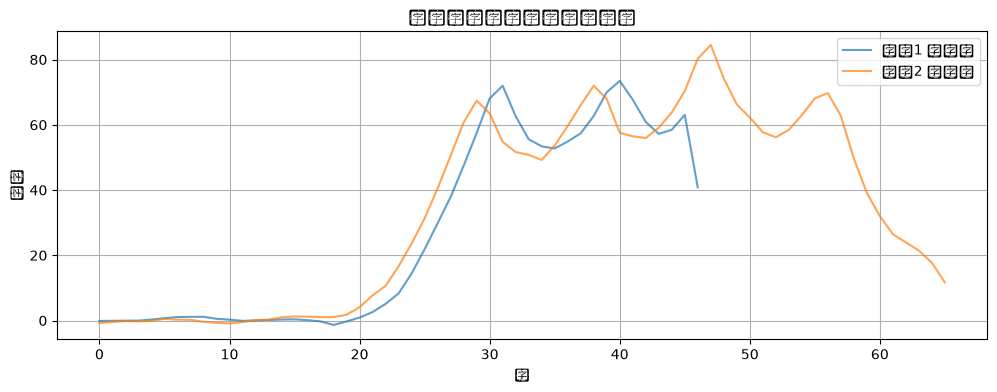

C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 21491 (\N{CJK UNIFIED IDEOGRAPH-53F3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 33109 (\N{CJK UNIFIED IDEOGRAPH-8155}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 22352 (\N{CJK UNIFIED IDEOGRAPH-5750}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\张轩睿\AppData\Local\Temp\ipykernel_16244\3877446801.py:56: UserWarning: Glyph 23545 (\N{CJK UNIFIE

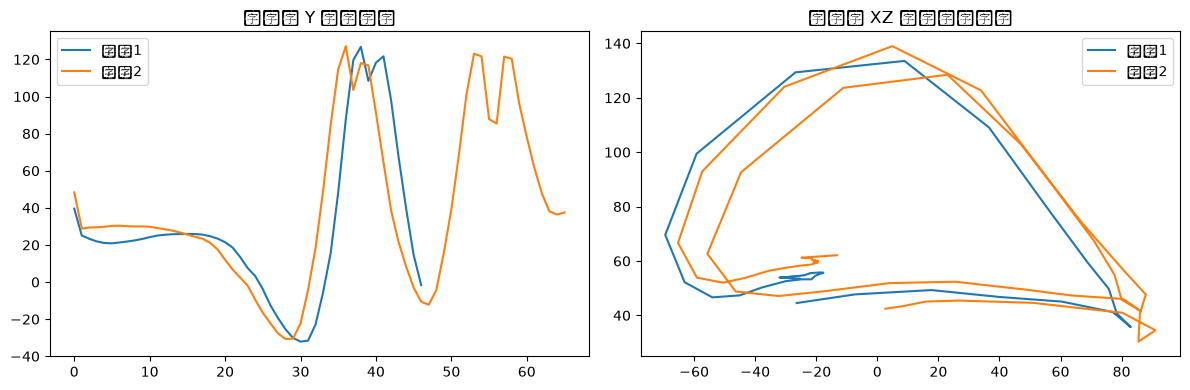


风格差异分析：
- 动作1的根高度标准差: 28.610
- 动作2的根高度标准差: 28.576
  动作1的上下起伏更大，可能更‘夸张’或‘活泼’


In [6]:
# 1. 加载两个动作序列（假设它们都是走路，但风格不同）
# 实际应用中，你需要根据文本描述或标签来筛选。
# 这里我们简单选择两个不同编号的文件作为示例。
motion1 = np.load(os.path.join(vecs_dir, '00001.npy'))
motion2 = np.load(os.path.join(vecs_dir, '00002.npy'))

# 查看它们的文本描述，确认动作类型
with open(os.path.join(texts_dir, '00001.txt'), 'r') as f:
    print("动作1描述:", f.readline().split('#')[0])
with open(os.path.join(texts_dir, '00002.txt'), 'r') as f:
    print("动作2描述:", f.readline().split('#')[0])

# 2. 计算统计量
mean1 = np.mean(motion1, axis=0)   # 每个特征的均值
std1 = np.std(motion1, axis=0)
mean2 = np.mean(motion2, axis=0)
std2 = np.std(motion2, axis=0)

# 3. 比较关节位置特征的差异（第3维到第65维是关节位置）
pos_start = 3
pos_end = 3 + 21*3  # 21个关节，每个3维

# 计算两个序列的关节位置均值的差异（欧氏距离）
pos_mean_diff = np.linalg.norm(mean1[pos_start:pos_end] - mean2[pos_start:pos_end])
print(f"关节位置均值的差异（欧氏距离）: {pos_mean_diff:.4f}")

# 计算关节位置标准差的差异
pos_std_diff = np.linalg.norm(std1[pos_start:pos_end] - std2[pos_start:pos_end])
print(f"关节位置标准差的差异（欧氏距离）: {pos_std_diff:.4f}")

# 4. 可视化：比较根节点高度（第2维）的变化模式
plt.figure(figsize=(12, 4))
plt.plot(motion1[:, 2], label='动作1 根高度', alpha=0.7)
plt.plot(motion2[:, 2], label='动作2 根高度', alpha=0.7)
plt.title('根节点高度随时间变化对比')
plt.xlabel('帧')
plt.ylabel('高度')
plt.legend()
plt.grid(True)
plt.show()

# 5. 可视化：比较右手腕的轨迹方差（风格差异的体现）
right_hand1 = get_joint_pos(motion1, 17)
right_hand2 = get_joint_pos(motion2, 17)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(right_hand1[:, 1], label='动作1')  # Y方向
axes[0].plot(right_hand2[:, 1], label='动作2')
axes[0].set_title('右手腕 Y 坐标对比')
axes[0].legend()

axes[1].plot(right_hand1[:, 0], right_hand1[:, 2], label='动作1')
axes[1].plot(right_hand2[:, 0], right_hand2[:, 2], label='动作2')
axes[1].set_title('右手腕 XZ 平面轨迹对比')
axes[1].legend()
plt.tight_layout()
plt.show()

# 6. 解读风格差异
print("\n风格差异分析：")
print(f"- 动作1的根高度标准差: {std1[2]:.3f}")
print(f"- 动作2的根高度标准差: {std2[2]:.3f}")
if std1[2] > std2[2]:
    print("  动作1的上下起伏更大，可能更‘夸张’或‘活泼’")
else:
    print("  动作2的上下起伏更大，可能更‘夸张’或‘活泼’")